# HMS — extended evaluation (no GPU needed)

Builds on `eval_top10.ipynb`, from the same archived out-of-fold predictions. Models: VIPEEGNet · EfficientNetB0 ·
PRISM (with TTA) · VIPEEGNet + PRISM blend.

| § | Test | Question |
|---|---|---|
| A | **Stricter statistics** | Are the differences real once rows from the same patient are treated as related, and after correcting for testing many things at once? |
| B | **Low-vote rows** (1–7 votes, a different rater pool) | Does the ranking of models hold outside the expert-rated rows? |
| C | **Decision curves** | Would acting on the model's alarms help, compared with alarming on everyone or no one? |
| D | **Error plausibility** | When a model is "wrong", did any experts agree with it? |
| E | **Calibration fix** | Does a fitted temperature (and class bias) lower KLD? |
| F | **Signal-quality subgroups** | Where does each model break: flat channels, high-amplitude artifact, short recordings, short stationary periods? |
| G | **Seed control** (runs once a second VIPEEGNet seed is archived) | Does PRISM add more than simply averaging two VIPEEGNet runs? |
| H | **Three-seed control** (runs once a third seed is archived) | With three models each, is two VIPEEGNets + PRISM better than three VIPEEGNets? |

Every tuned number (blend weight, temperature) is fitted on the other four folds and applied to the held-out fold.
Outputs: `results/comparisons/extended_eval/` (CSVs, figures, `report.md`).

In [1]:
PROJECT_DIR = '~/hms'
MODELS = [
    ['vipeegnet_groupkfold_v1', 'VIPEEGNet'],
    ['effnetb0_native_v1',      'EfficientNetB0'],
    ['prism_wf5_tta_v1',        'PRISM'],
    ['blend_vip_prism_wf5_v1',  'VIPEEGNet + PRISM'],
]
SEED2_TAG = 'vipeegnet_seed2025_v1'      # section G runs only if this archive exists
SEED3_TAG = 'vipeegnet_seed2026_v1'      # section H runs only if this archive exists too
EEG_CACHE = '~/hms/eeg_cache_v2'          # section F needs it; skipped if missing
N_BOOT = 1000
OUT_NAME = 'extended_eval'

In [2]:
# Parameters
PROJECT_DIR = "/home/nfs/jhb-dehzangi/ws04/gs1147/hms"


In [3]:
import os, sys, json, numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import norm as norm_dist
from sklearn.metrics import roc_auc_score, f1_score
P = os.path.abspath(os.path.expanduser(PROJECT_DIR)); EEG_CACHE = os.path.abspath(os.path.expanduser(EEG_CACHE))
sys.path.insert(0, f'{P}/results'); os.environ['HMS_RESULTS'] = f'{P}/results'
from load_results import load_oof
CLASS = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']; SZ, OTH = 0, 5
VOTE_COLS = ['seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote']
OUTD = f'{P}/results/comparisons/{OUT_NAME}'; os.makedirs(OUTD, exist_ok=True)
TRAIN = pd.read_csv(f'{P}/hms-data/train.csv')
pid = TRAIN.groupby('eeg_id').patient_id.first()
NAMES = [n for _, n in MODELS]; REF = NAMES[0]; BLEND = NAMES[3]
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
COL = {'VIPEEGNet': '#2a78d6', 'EfficientNetB0': '#eb6834', 'PRISM': '#1baf7a', 'VIPEEGNet + PRISM': '#e87ba4',
       'VIPEEGNet seed 2': '#6250d6', 'VIPEEGNet 2 seeds': '#eda100', 'VIPEEGNet 2 seeds + PRISM': '#008300'}
SURF, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'font.size': 10,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False})
def save(fig, name): fig.savefig(f'{OUTD}/{name}', dpi=150); plt.close(fig); display(Image(f'{OUTD}/{name}'))
def legend_below(fig, ax, n): fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=n, fontsize=9)
def kld(t, p): t = np.clip(t, 1e-7, 1); p = np.clip(p, 1e-7, 1); return (t * np.log(t / p)).sum(1)
def norm(p): p = np.clip(p, 1e-7, 1); return p / p.sum(1, keepdims=True)
def geo(a, b, w):
    q = np.exp((1 - w) * np.log(np.clip(a, 1e-7, 1)) + w * np.log(np.clip(b, 1e-7, 1))); return q / q.sum(1, keepdims=True)

def keyed(tag, subset):
    yt, yp, m = load_oof(tag, subset)
    v = np.rint(yt * m.votes.values[:, None]).astype(int)
    m['key'] = m.eeg_id.astype(str) + ':' + pd.Series([','.join(map(str, r)) for r in v]).values
    assert m.key.is_unique, f'{tag}: duplicate row keys'
    return yt, norm(yp), m.reset_index(drop=True)

def align(tags_names, subset):
    """Put every model's predictions in the first model's row order. Returns yt, meta, preds, folds."""
    base = None; preds, folds = {}, {}
    for tag, name in tags_names:
        yt_, yp_, m_ = keyed(tag, subset)
        if base is None: base = (yt_, m_); order = np.arange(len(m_))
        else:
            assert set(m_.key) == set(base[1].key), f'{name} was scored on different {subset} rows'
            order = pd.Series(np.arange(len(m_)), index=m_.key)[base[1].key].values
            assert np.allclose(yt_[order], base[0], atol=1e-5), f'{name}: labels differ'
        preds[name] = yp_[order]; folds[name] = m_.fold.values[order]
    yt, meta = base; meta = meta.copy(); meta['patient_id'] = meta.eeg_id.map(pid).values
    return yt, meta, preds, folds

yt, meta, preds, folds = align(MODELS, 'hq')
N = len(yt); Y = yt.argmax(1); VOTES = np.rint(yt * meta.votes.values[:, None]).astype(int)
pats, inv = np.unique(meta.patient_id.values, return_inverse=True); NP = len(pats)
rng = np.random.default_rng(0)
PAT_ROWS = [np.where(inv == j)[0] for j in range(NP)]
BS_ROWS = [np.concatenate([PAT_ROWS[j] for j in s]) for s in rng.integers(0, NP, (N_BOOT, NP))]
REPORT = [f'# HMS — extended evaluation ({pd.Timestamp.today().date()})',
          f'{N:,} rows with >=10 votes, {NP:,} patients. CIs and p-values resample whole patients ({N_BOOT} resamples).']
def mdt(df):
    try: return df.round(4).to_markdown()
    except ImportError: return '```\n' + df.round(4).to_string() + '\n```'
print(f'{N:,} HQ rows | {NP:,} patients | models: {NAMES}')

6,350 HQ rows | 1,063 patients | models: ['VIPEEGNet', 'EfficientNetB0', 'PRISM', 'VIPEEGNet + PRISM']


## A. Stricter statistics
Each metric is recomputed on 1,000 resamples of whole patients (the same resamples for every model, so differences are
paired). CI = percentile interval; p = two-sided, from the bootstrap standard error (difference / SE, normal).
**Holm** correction is applied across all comparisons in the table.

In [4]:
IIIC = np.array([0, 1, 2, 3, 4])
def metrics(t, y, p):
    yy = (y[:, None] == np.arange(6))
    return {'KLD': kld(t, p).mean(), 'accuracy %': (p.argmax(1) == y).mean() * 100,
            'macro-F1 %': f1_score(y, p.argmax(1), average='macro', labels=range(6)) * 100,
            'macro-AUROC': np.mean([roc_auc_score(yy[:, c], p[:, c]) for c in range(6)]),
            'seizure AUROC': roc_auc_score(y == SZ, p[:, SZ]), 'harmful-vs-Other AUROC': roc_auc_score(y != OTH, 1 - p[:, OTH])}
LOWER = {'KLD'}
point = {n: metrics(yt, Y, p) for n, p in preds.items()}
boot = {n: [] for n in NAMES}
for r in BS_ROWS:
    for n, p in preds.items(): boot[n].append(metrics(yt[r], Y[r], p[r]))
boot = {n: pd.DataFrame(b) for n, b in boot.items()}
COMPARE = [(n, REF) for n in NAMES[1:]] + [(BLEND, 'PRISM')]
rows = []
for a, b in COMPARE:
    for mt in point[REF]:
        d = boot[a][mt] - boot[b][mt]; diff = point[a][mt] - point[b][mt]
        pval = float(2 * norm_dist.sf(abs(diff) / max(d.std(ddof=1), 1e-12)))
        better = (diff < 0) if mt in LOWER else (diff > 0)
        rows.append({'comparison': f'{a} vs {b}', 'metric': mt, 'first': point[a][mt], 'second': point[b][mt],
                     'difference': diff, 'CI low': np.percentile(d, 2.5), 'CI high': np.percentile(d, 97.5),
                     'p': pval, 'first is better': better})
SA = pd.DataFrame(rows)
o = np.argsort(SA['p'].values); m_ = len(SA); adj = np.empty(m_); run = 0
for rank, i in enumerate(o): run = max(run, min(1, (m_ - rank) * SA['p'].values[i])); adj[i] = run
SA['p (Holm)'] = adj; SA['significant (Holm < 0.05)'] = SA['p (Holm)'] < 0.05
SA.to_csv(f'{OUTD}/a_statistics.csv', index=False)
REPORT += ['## A. Stricter statistics', mdt(SA.set_index(['comparison', 'metric']))]
display(SA.set_index(['comparison', 'metric']).round(4))

first   second  difference   CI low  CI high       p  first is better  p (Holm)  significant (Holm < 0.05)
comparison                     metric                                                                                                                              
EfficientNetB0 vs VIPEEGNet    KLD                      0.4648   0.2217      0.2431   0.2172   0.2663  0.0000            False    0.0000                       True
                               accuracy %              67.3386  77.2441     -9.9055 -11.6686  -7.9873  0.0000            False    0.0000                       True
                               macro-F1 %              55.5827  66.2628    -10.6801 -13.3107  -8.1331  0.0000            False    0.0000                       True
                               macro-AUROC              0.9063   0.9564     -0.0501  -0.0564  -0.0435  0.0000            False    0.0000                       True
                               seizure AUROC            0.9375   0.9751     -0.0376  -0.0517  -0.0260  0.0000            False    0.0000                       True
                               harmful-vs-Other AUROC   0.8741   0.9291     -0.0550  -0.0647  -0.0456  0.0000            False    0.0000                       True
PRISM vs VIPEEGNet             KLD                      0.2732   0.2217      0.0516   0.0420   0.0638  0.0000            False    0.0000                       True
                               accuracy %              74.8189  77.2441     -2.4252  -3.4537  -1.3897  0.0000            False    0.0001                       True
                               macro-F1 %              62.5268  66.2628     -3.7361  -5.6550  -1.9564  0.0000            False    0.0003                       True
                               macro-AUROC              0.9442   0.9564     -0.0122  -0.0153  -0.0091  0.0000            False    0.0000                       True
                               seizure AUROC            0.9649   0.9751     -0.0102  -0.0161  -0.0042  0.0009            False    0.0045                       True
                               harmful-vs-Other AUROC   0.9125   0.9291     -0.0166  -0.0240  -0.0097  0.0000            False    0.0000                       True
VIPEEGNet + PRISM vs VIPEEGNet KLD                      0.2177   0.2217     -0.0040  -0.0056  -0.0023  0.0000             True    0.0000                       True
                               accuracy %              77.8110  77.2441      0.5669   0.1554   1.0106  0.0073             True    0.0220                       True
                               macro-F1 %              66.9880  66.2628      0.7252  -0.0323   1.4886  0.0694             True    0.1388                      False
                               macro-AUROC              0.9575   0.9564      0.0011   0.0005   0.0017  0.0007             True    0.0043                       True
                               seizure AUROC            0.9757   0.9751      0.0006  -0.0005   0.0017  0.3137             True    0.3137                      False
                               harmful-vs-Other AUROC   0.9307   0.9291      0.0016   0.0005   0.0028  0.0041             True    0.0163                       True
VIPEEGNet + PRISM vs PRISM     KLD                      0.2177   0.2732     -0.0555  -0.0666  -0.0469  0.0000             True    0.0000                       True
                               accuracy %              77.8110  74.8189      2.9921   2.0798   3.9400  0.0000             True    0.0000                       True
                               macro-F1 %              66.9880  62.5268      4.4613   2.8621   6.2061  0.0000             True    0.0000                       True
                               macro-AUROC              0.9575   0.9442      0.0133   0.0107   0.0160  0.0000             True    0.0000                       True
                               seizure AUROC            0.9757   0.9649      0.0108   0.0058   0.0159  0.0000            

## B. Low-vote rows (1–7 votes)
These rows come mostly from a different, non-expert rater pool and have noisy labels, so absolute KLD is high for every
model. The question is whether the **ranking** holds. The blend is rebuilt on all rows with the same rule as before:
geometric blend, weight on PRISM chosen on the other four folds' ≥10-vote rows.

In [5]:
ALL_MODELS = [m for m in MODELS if m[1] != BLEND]
ya, ma, pa, fa = align(ALL_MODELS, 'all')
hq_a = ma.votes.values >= 10; fold_a = fa[REF]; W = np.round(np.arange(0, 1.001, 0.05), 2); wts = {}
blend_all = np.zeros_like(ya)
for k in np.unique(fold_a):
    tr = hq_a & (fold_a != k)
    w = W[np.argmin([kld(ya[tr], geo(pa[REF][tr], pa['PRISM'][tr], w)).mean() for w in W])]; wts[int(k)] = float(w)
    te = fold_a == k; blend_all[te] = geo(pa[REF][te], pa['PRISM'][te], w)
pa[BLEND] = blend_all
print('blend weight on PRISM per fold (chosen on other folds\' >=10-vote rows):', wts)
low = ~hq_a; nv = ma.votes.values
bk = pd.cut(nv, [0, 1, 2, 5, 9], labels=['1 vote', '2 votes', '3-5 votes', '6-7 votes'])
Ya = ya.argmax(1); rows = []
for n in NAMES:
    for lev in list(bk.categories) + ['all low-vote rows', '>=10 votes (for reference)']:
        msk = (hq_a if lev.startswith('>=') else low if lev == 'all low-vote rows' else (bk == lev))
        rows.append({'model': n, 'rows': lev, 'n': int(msk.sum()), 'KLD': kld(ya[msk], pa[n][msk]).mean(),
                     'accuracy vs plurality %': (pa[n][msk].argmax(1) == Ya[msk]).mean() * 100})
SB = pd.DataFrame(rows)
# paired patient bootstrap of KLD difference vs VIPEEGNet on the low-vote rows
lp = ma.eeg_id.map(pid).values[low]; up, iv = np.unique(lp, return_inverse=True); cnt = np.bincount(iv)
bs = rng.integers(0, len(up), (N_BOOT, len(up))); kref = kld(ya[low], pa[REF][low]); diffs = []
for n in NAMES[1:]:
    s = np.bincount(iv, kld(ya[low], pa[n][low]) - kref); d = s[bs].sum(1) / cnt[bs].sum(1)
    diffs.append({'model': n, 'KLD minus VIPEEGNet (low-vote rows)': (kld(ya[low], pa[n][low]) - kref).mean(),
                  'CI low': np.percentile(d, 2.5), 'CI high': np.percentile(d, 97.5)})
SBd = pd.DataFrame(diffs).set_index('model')
SB.to_csv(f'{OUTD}/b_low_vote_rows.csv', index=False); SBd.to_csv(f'{OUTD}/b_low_vote_differences.csv')
tb = SB.pivot_table(index=['rows', 'n'], columns='model', values='KLD', sort=False)[NAMES]
ta = SB.pivot_table(index=['rows', 'n'], columns='model', values='accuracy vs plurality %', sort=False)[NAMES]
REPORT += ['## B. Low-vote rows', f'Blend weights per fold: {wts}', '### KLD', mdt(tb), '### Accuracy vs plurality %', mdt(ta),
           '### Difference vs VIPEEGNet (patient CI)', mdt(SBd)]
print('KLD'); display(tb.round(4)); print('accuracy vs plurality % (ties broken by class order)'); display(ta.round(1)); display(SBd.round(4))

blend weight on PRISM per fold (chosen on other folds' >=10-vote rows): {0: 0.2, 1: 0.2, 2: 0.2, 3: 0.2, 4: 0.2}
KLD


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
rows,n,,,,
1 vote,3452,0.4071,0.5483,0.4396,0.4039
2 votes,2078,0.5441,0.6521,0.5999,0.5429
3-5 votes,8161,0.9433,0.7474,1.0349,0.9458
6-7 votes,142,0.3739,0.4454,0.4702,0.3753
all low-vote rows,13833,0.7437,0.6803,0.8152,0.7442
>=10 votes (for reference),6350,0.2217,0.4648,0.2732,0.2177


accuracy vs plurality % (ties broken by class order)


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
rows,n,,,,
1 vote,3452,87.7,81.1,86.2,87.9
2 votes,2078,68.9,69.4,67.5,68.7
3-5 votes,8161,55.8,69.2,54.6,55.6
6-7 votes,142,69.0,69.7,64.8,69.7
all low-vote rows,13833,65.9,72.2,64.5,65.8
>=10 votes (for reference),6350,77.2,67.3,74.8,77.8


,KLD minus VIPEEGNet (low-vote rows),CI low,CI high
model,,,
EfficientNetB0,-0.0634,-0.1116,-0.0182
PRISM,0.0716,0.0566,0.0886
VIPEEGNet + PRISM,0.0005,-0.0024,0.0038


## C. Decision curves (net benefit)
Net benefit = true positives/N − false positives/N × pt/(1 − pt), where pt is the probability at which a clinician would
act (alarm/review). A model is useful at pt when its curve is above both "alarm on everyone" and "alarm on no one" (0).

alarm on everyone  alarm on no one  VIPEEGNet  EfficientNetB0  PRISM  VIPEEGNet + PRISM
task                                threshold                                                                                         
Seizure                             0.05                   -0.64              0.0       3.46            2.76   3.53               3.46
                                    0.10                   -6.23              0.0       3.07            1.91   3.01               3.13
                                    0.20                  -19.51              0.0       2.63            0.57   2.40               2.68
                                    0.30                  -36.58              0.0       2.31           -0.76   1.86               2.38
                                    0.50                  -91.21              0.0       1.50           -3.50   0.90               1.43
Harmful pattern (any IIIC) vs Other 0.05                   47.58              0.0      47.95           47.84  47.93              47.96
                                    0.10                   44.67              0.0      46.01           45.69  45.99              46.05
                                    0.20                   37.76              0.0      42.59           41.50  42.57              42.64
                                    0.30                   28.86              0.0      39.74           37.29  39.42              39.90
                                    0.50                    0.41              0.0      34.27           28.25  32.82              34.30

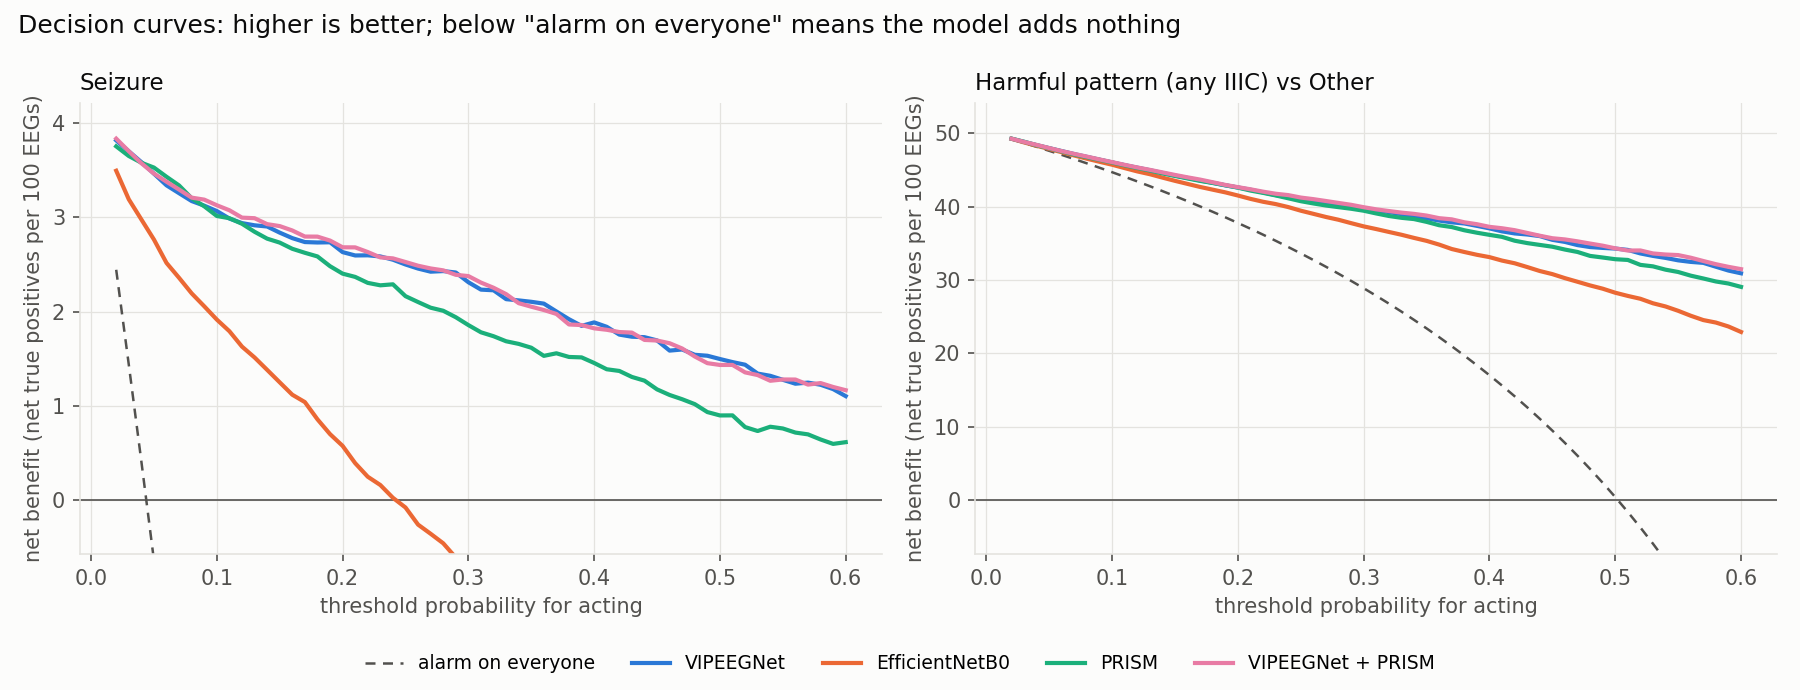

In [6]:
PT = np.round(np.arange(0.02, 0.61, 0.01), 2)
TASKS = {'Seizure': (Y == SZ, lambda p: p[:, SZ]), 'Harmful pattern (any IIIC) vs Other': (Y != OTH, lambda p: 1 - p[:, OTH])}
def net_benefit(y, s, pt):
    a = s >= pt; return (a & y).mean() - (a & ~y).mean() * pt / (1 - pt)
rows = []
for t, (y, f) in TASKS.items():
    prev = y.mean()
    for pt in PT:
        r = {'task': t, 'threshold': pt, 'alarm on everyone': prev - (1 - prev) * pt / (1 - pt), 'alarm on no one': 0.0}
        for n, p in preds.items(): r[n] = net_benefit(y, f(p), pt)
        rows.append(r)
SC = pd.DataFrame(rows); SC.to_csv(f'{OUTD}/c_decision_curves.csv', index=False)
tc = SC[SC.threshold.isin([0.05, 0.10, 0.20, 0.30, 0.50])].set_index(['task', 'threshold'])
REPORT += ['## C. Net benefit at selected thresholds (x100 = net true positives per 100 EEGs)', mdt(tc * 100)]
display((tc * 100).round(2))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, t in zip(axs, TASKS):
    s = SC[SC.task == t]
    ax.plot(s.threshold, s['alarm on everyone'] * 100, color=INK2, lw=1.2, ls=(0, (4, 3)), label='alarm on everyone')
    ax.axhline(0, color=INK2, lw=0.8)
    for n in NAMES: ax.plot(s.threshold, s[n] * 100, lw=2, color=COL[n], label=n)
    top = s[NAMES].values.max() * 100; ax.set_ylim(-top * 0.15, top * 1.1)
    ax.set_xlabel('threshold probability for acting'); ax.set_ylabel('net benefit (net true positives per 100 EEGs)')
    ax.set_title(t, loc='left', fontsize=11, color=INK)
fig.suptitle('Decision curves: higher is better; below "alarm on everyone" means the model adds nothing', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(NAMES) + 1); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig_c_decision_curves.png')

## D. Error plausibility
For each wrong top prediction: what share of the experts voted for the class the model chose?
"No expert chose it" errors are the ones a reviewer would call clearly wrong.

per 1,000 EEGs


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
votes for the model's class,,,,
no expert chose it,5.8,58.1,12.1,4.7
1-24% of experts,76.1,130.7,90.6,73.5
25-49% of experts,139.7,134.3,143.1,137.8
50%+ (a tie at the top),6.0,3.5,6.0,5.8


% of errors


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
votes for the model's class,,,,
no expert chose it,2.6,17.8,4.8,2.1
1-24% of experts,33.4,40.0,36.0,33.1
25-49% of experts,61.4,41.1,56.8,62.1
50%+ (a tie at the top),2.6,1.1,2.4,2.6


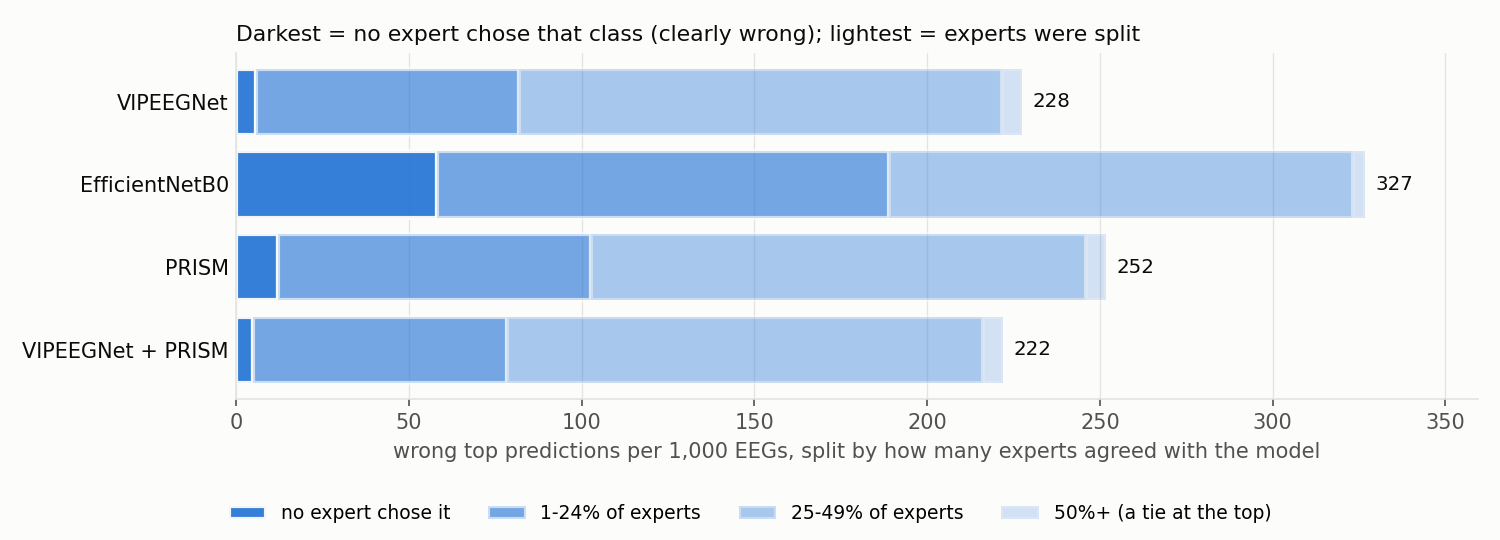

In [7]:
EB = ['no expert chose it', '1-24% of experts', '25-49% of experts', '50%+ (a tie at the top)']
rows = []
for n, p in preds.items():
    q = p.argmax(1); wrong = q != Y; sh = yt[np.arange(N), q][wrong]
    cat = pd.cut(sh, [-1e-9, 1e-9, 0.25, 0.5, 1.01], right=False, labels=EB)
    vc = pd.Series(cat).value_counts().reindex(EB, fill_value=0)
    for k in EB: rows.append({'model': n, 'votes for the model\'s class': k, 'errors': int(vc[k]),
                              '% of errors': vc[k] / wrong.sum() * 100, 'per 1,000 EEGs': vc[k] / N * 1000})
SD = pd.DataFrame(rows); SD.to_csv(f'{OUTD}/d_error_plausibility.csv', index=False)
td = SD.pivot(index='votes for the model\'s class', columns='model', values='per 1,000 EEGs').loc[EB, NAMES]
tdp = SD.pivot(index='votes for the model\'s class', columns='model', values='% of errors').loc[EB, NAMES]
REPORT += ['## D. Error plausibility (per 1,000 EEGs)', mdt(td), '### Share of each model\'s errors %', mdt(tdp)]
print('per 1,000 EEGs'); display(td.round(1)); print('% of errors'); display(tdp.round(1))
fig, ax = plt.subplots(figsize=(10, 3.6)); left = np.zeros(len(NAMES))
shades = [0.95, 0.65, 0.4, 0.2]
for k, a in zip(EB, shades):
    v = td.loc[k].values
    ax.barh(np.arange(len(NAMES))[::-1], v, left=left, color=COL[REF], alpha=a, edgecolor=SURF, linewidth=2, label=k)
    left += v
for i, n in enumerate(NAMES):
    ax.text(left[i] + 3, len(NAMES) - 1 - i, f'{left[i]:.0f}', va='center', color=INK, fontsize=9.5)
ax.set_yticks(np.arange(len(NAMES))[::-1], NAMES); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
ax.set_xlabel('wrong top predictions per 1,000 EEGs, split by how many experts agreed with the model')
ax.set_title('Darkest = no expert chose that class (clearly wrong); lightest = experts were split', loc='left', fontsize=10.5, color=INK)
ax.set_xlim(0, left.max() * 1.1)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=9); fig.tight_layout(rect=(0, 0.1, 1, 1))
save(fig, 'fig_d_error_plausibility.png')

## E. Calibration fix
Two post-hoc corrections on each model's probabilities, fitted on the other four folds (≥10-vote rows) and applied to the
held-out fold: **temperature** T (q ∝ p^(1/T); T < 1 sharpens) and **temperature + per-class bias** (7 numbers).

In [8]:
def apply(p, T, b=None):
    z = np.log(np.clip(p, 1e-7, 1)) / T + (0 if b is None else b); z -= z.max(1, keepdims=True); q = np.exp(z)
    return q / q.sum(1, keepdims=True)
rows, cal_preds = [], {}
for n, p in preds.items():
    f = folds[n] if n != BLEND else folds[REF]; qT = np.zeros_like(p); qTB = np.zeros_like(p); Ts = []
    for k in np.unique(f):
        tr, te = f != k, f == k
        T = minimize_scalar(lambda lt: kld(yt[tr], apply(p[tr], np.exp(lt))).mean(), bounds=(-1.5, 1.5), method='bounded').x
        res = minimize(lambda v: kld(yt[tr], apply(p[tr], np.exp(v[0]), v[1:])).mean(), np.r_[T, np.zeros(6)], method='L-BFGS-B')
        qT[te] = apply(p[te], np.exp(T)); qTB[te] = apply(p[te], np.exp(res.x[0]), res.x[1:]); Ts.append(np.exp(T))
    cal_preds[n] = qTB
    k0, k1, k2 = kld(yt, p), kld(yt, qT), kld(yt, qTB)
    s = np.bincount(inv, k0 - k2); c = np.bincount(inv)
    bsI = rng.integers(0, NP, (N_BOOT, NP)); g = s[bsI].sum(1) / c[bsI].sum(1)
    rows.append({'model': n, 'KLD as is': k0.mean(), 'KLD + temperature': k1.mean(), 'KLD + temperature + class bias': k2.mean(),
                 'gain (as is - T+bias)': (k0 - k2).mean(), 'gain CI low': np.percentile(g, 2.5), 'gain CI high': np.percentile(g, 97.5),
                 'fitted T per fold': ', '.join(f'{t:.3f}' for t in Ts)})
SE = pd.DataFrame(rows).set_index('model'); SE.to_csv(f'{OUTD}/e_calibration_fix.csv')
REPORT += ['## E. Calibration fix (T < 1 = predictions sharpened)', mdt(SE)]
display(SE.round(4))

,KLD as is,KLD + temperature,KLD + temperature + class bias,gain (as is - T+bias),gain CI low,gain CI high,fitted T per fold
model,,,,,,,
VIPEEGNet,0.2217,0.2212,0.2217,0.0000,-0.0007,0.0008,"1.044, 1.036, 1.046, 1.036, 1.035"
EfficientNetB0,0.4648,0.4235,0.3695,0.0953,0.0808,0.1103,"1.338, 1.368, 1.363, 1.384, 1.375"
PRISM,0.2732,0.2690,0.2673,0.0059,0.0035,0.0085,"1.113, 1.115, 1.114, 1.104, 1.108"
VIPEEGNet + PRISM,0.2177,0.2174,0.2174,0.0003,-0.0005,0.0011,"1.039, 1.033, 1.042, 1.030, 1.030"


## F. Signal-quality subgroups
For each ≥10-vote row, the 50 s validation window (the same middle sub-window the models were scored on) is read from the
EEG cache (18 bipolar channels, filtered). Subgroups: flat or missing channels, high-amplitude artifact, recording length,
and stationary-period size (how many labelled sub-windows share the same votes).

flat or missing channels


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
none,6331,0.2214,0.4647,0.2732,0.2175
1,6,0.2028,0.4072,0.1855,0.1861
2+,13,0.3514,0.5172,0.3417,0.3350


artifact amplitude (tertile)


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
low,2117,0.2028,0.4202,0.2632,0.2003
middle,2116,0.2246,0.4505,0.2686,0.2198
high,2117,0.2376,0.5236,0.2879,0.2331


recording length (tertile)


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
short,2117,0.1889,0.3879,0.2404,0.1860
middle,2116,0.2239,0.4639,0.2683,0.2180
long,2117,0.2522,0.5426,0.3111,0.2492


stationary period


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
1 window,1334,0.2018,0.4273,0.2603,0.1988
2-5,3099,0.2121,0.4611,0.2615,0.2077
6+,1917,0.2509,0.4969,0.3012,0.2471


signal-quality summary:


,count,mean,std,min,25%,50%,75%,max
eeg_id,6350.0,2.134764e+09,1.244944e+09,568657.0,1.035991e+09,2.106136e+09,3.216229e+09,4.294859e+09
flat channels,6350.0,1.000000e-02,3.000000e-01,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.800000e+01
amplitude p99 (uV),6350.0,5.678000e+01,7.493000e+01,0.0,2.824000e+01,3.949000e+01,5.897000e+01,1.253440e+03
saturated samples %,6350.0,3.000000e-02,2.200000e-01,0.0,0.000000e+00,0.000000e+00,0.000000e+00,5.490000e+00
recording length (s),6350.0,1.064300e+02,1.668100e+02,50.0,5.400000e+01,6.600000e+01,1.035000e+02,3.422000e+03
sub-windows in stationary period,6350.0,6.290000e+00,1.770000e+01,1.0,2.000000e+00,3.000000e+00,6.000000e+00,7.430000e+02


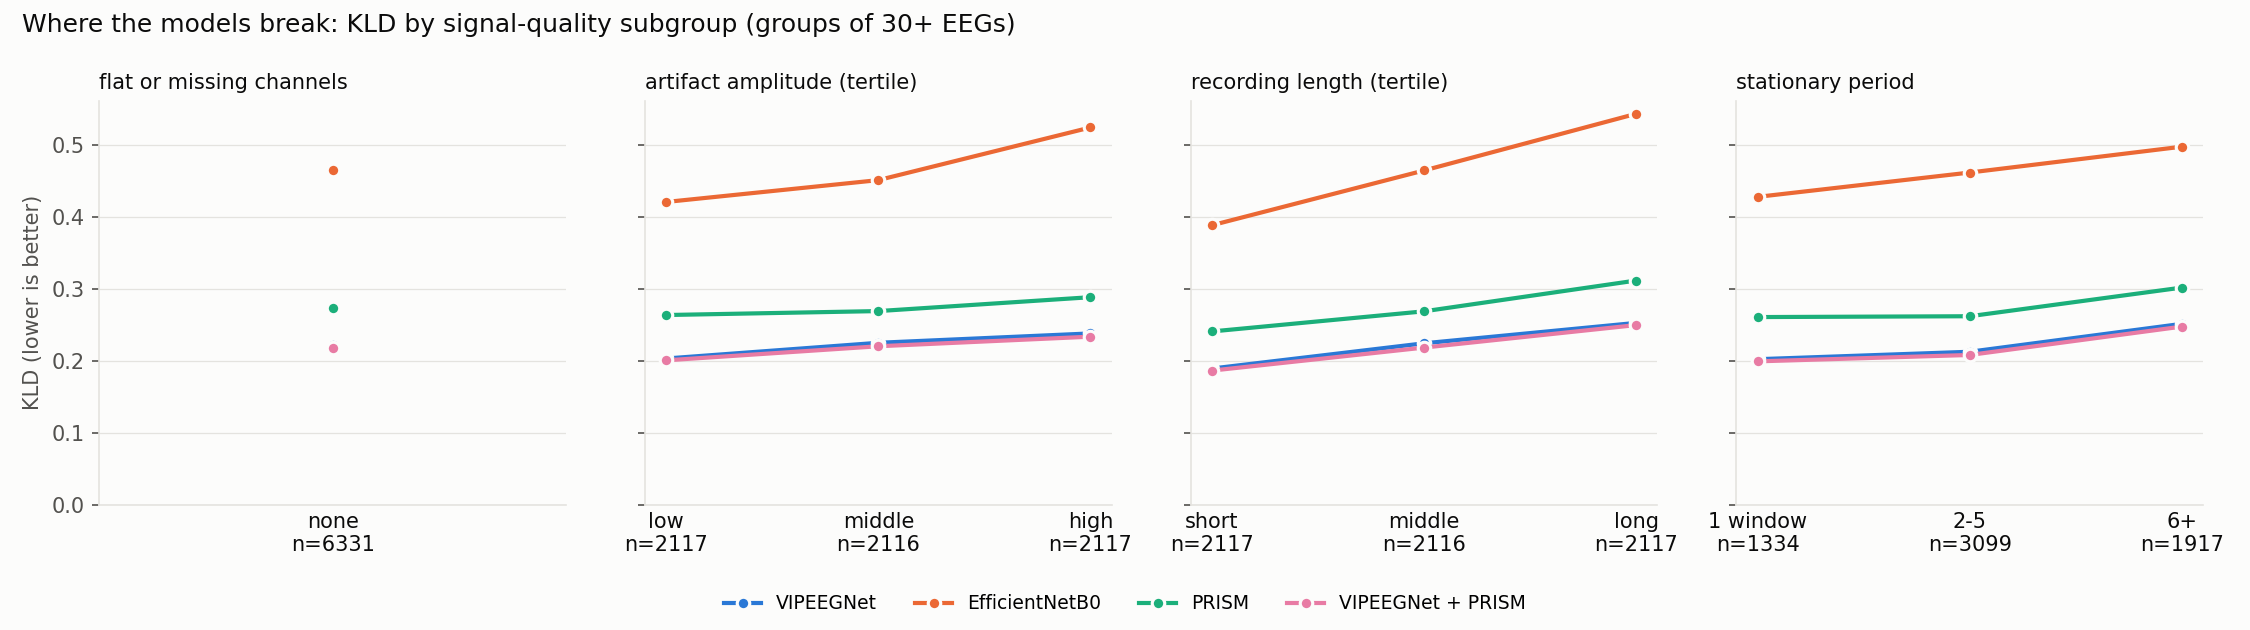

In [9]:
SF = None
if not os.path.isdir(EEG_CACHE):
    print(f'EEG cache not found at {EEG_CACHE} - section F skipped')
else:
    key_cols = ['eeg_id'] + VOTE_COLS
    look = {tuple(int(x) for x in k): g.sort_values('eeg_sub_id', kind='stable')['eeg_label_offset_seconds'].to_numpy()
            for k, g in TRAIN[key_cols + ['eeg_sub_id', 'eeg_label_offset_seconds']].groupby(key_cols, sort=False)}
    q = []
    for e, v in zip(meta.eeg_id.values, VOTES):
        offs = look[(int(e),) + tuple(int(x) for x in v)]; off = offs[len(offs) // 2]
        x = np.load(f'{EEG_CACHE}/{int(e)}.npy', mmap_mode='r')
        w = np.asarray(x[:, int(round(off * 200)):int(round((off + 50) * 200))], dtype=np.float32)
        a = np.abs(w)
        q.append({'flat channels': int((w.std(1) < 0.5).sum()), 'amplitude p99 (uV)': float(np.median(np.percentile(a, 99, axis=1))),
                  'saturated samples %': float((a > 900).mean() * 100), 'recording length (s)': x.shape[1] / 200,
                  'sub-windows in stationary period': len(offs)})
    QF = pd.DataFrame(q); QF.insert(0, 'eeg_id', meta.eeg_id.values); QF.to_csv(f'{OUTD}/f_signal_quality_per_row.csv', index=False)
    groups = {
        'flat or missing channels': pd.cut(QF['flat channels'], [-1, 0, 1, 99], labels=['none', '1', '2+']),
        'artifact amplitude (tertile)': pd.qcut(QF['amplitude p99 (uV)'], 3, labels=['low', 'middle', 'high']),
        'recording length (tertile)': pd.qcut(QF['recording length (s)'].rank(method='first'), 3, labels=['short', 'middle', 'long']),
        'stationary period': pd.cut(QF['sub-windows in stationary period'], [0, 1, 5, 1e9], labels=['1 window', '2-5', '6+']),
    }
    rows = []
    for gname, g in groups.items():
        for lev in g.cat.categories:
            msk = (g == lev).values
            if msk.sum() == 0: continue
            for n, p in preds.items():
                rows.append({'grouping': gname, 'level': lev, 'n': int(msk.sum()), 'model': n,
                             'KLD': kld(yt[msk], p[msk]).mean(), 'accuracy %': (p[msk].argmax(1) == Y[msk]).mean() * 100})
    SF = pd.DataFrame(rows); SF.to_csv(f'{OUTD}/f_signal_quality_subgroups.csv', index=False)
    REPORT.append('## F. Signal-quality subgroups (KLD)')
    for gname in groups:
        t = SF[SF.grouping == gname].pivot_table(index=['level', 'n'], columns='model', values='KLD', sort=False, observed=True)[NAMES]
        print(gname); display(t.round(4)); REPORT += [f'### {gname}', mdt(t)]
    print('signal-quality summary:'); display(QF.describe().T.round(2))
    fig, axs = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
    for ax, gname in zip(axs, groups):
        s = SF[(SF.grouping == gname) & (SF.n >= 30)]; levels = list(dict.fromkeys(s.level)); xx = np.arange(len(levels))   # groups < 30 EEGs: table only
        ns = s[s.model == REF].set_index('level').loc[levels, 'n'].values
        for n in NAMES:
            ax.plot(xx, s[s.model == n].set_index('level').loc[levels, 'KLD'].values, '-o', lw=2, ms=6, color=COL[n], mec=SURF, mew=1.5, label=n)
        ax.set_xticks(xx, [f'{l}\nn={k}' for l, k in zip(levels, ns)]); ax.tick_params(axis='x', colors=INK, length=0)
        ax.set_title(gname, loc='left', fontsize=10, color=INK); ax.grid(axis='x', visible=False)
    axs[0].set_ylabel('KLD (lower is better)'); axs[0].set_ylim(bottom=0)
    fig.suptitle('Where the models break: KLD by signal-quality subgroup (groups of 30+ EEGs)', x=0.01, ha='left', fontsize=12, color=INK)
    legend_below(fig, axs[0], len(NAMES)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig_f_signal_quality.png')

## G. Seed control
Retraining VIPEEGNet with another seed changes its score by itself. The fair test of PRISM's contribution:
**VIPEEGNet + PRISM** vs **the average of two VIPEEGNet seeds** (both are two-model ensembles). Also reported: seed-to-seed
difference, and both seeds + PRISM. Runs only when the second seed's archive exists.

,KLD,CI low,CI high,accuracy %
model,,,,
VIPEEGNet,0.2217,0.2120,0.2317,77.2441
VIPEEGNet seed 2,0.2238,0.2135,0.2342,77.4646
VIPEEGNet 2 seeds,0.2162,0.2066,0.2260,77.7008
VIPEEGNet + PRISM,0.2177,0.2084,0.2275,77.8110
VIPEEGNet 2 seeds + PRISM,0.2143,0.2048,0.2241,77.5748


,comparison,KLD difference,CI low,CI high,p
test,,,,,
seed-to-seed noise,VIPEEGNet seed 2 - VIPEEGNet,0.0021,-0.0023,0.0064,0.3574
gain from a second VIPEEGNet,VIPEEGNet 2 seeds - VIPEEGNet,-0.0055,-0.0077,-0.0035,0.0000
gain from adding PRISM,VIPEEGNet + PRISM - VIPEEGNet,-0.0040,-0.0057,-0.0023,0.0000
KEY: PRISM vs a second VIPEEGNet,VIPEEGNet + PRISM - VIPEEGNet 2 seeds,0.0015,-0.0005,0.0035,0.1444
PRISM on top of two seeds,VIPEEGNet 2 seeds + PRISM - VIPEEGNet 2 seeds,-0.0020,-0.0031,-0.0008,0.0007


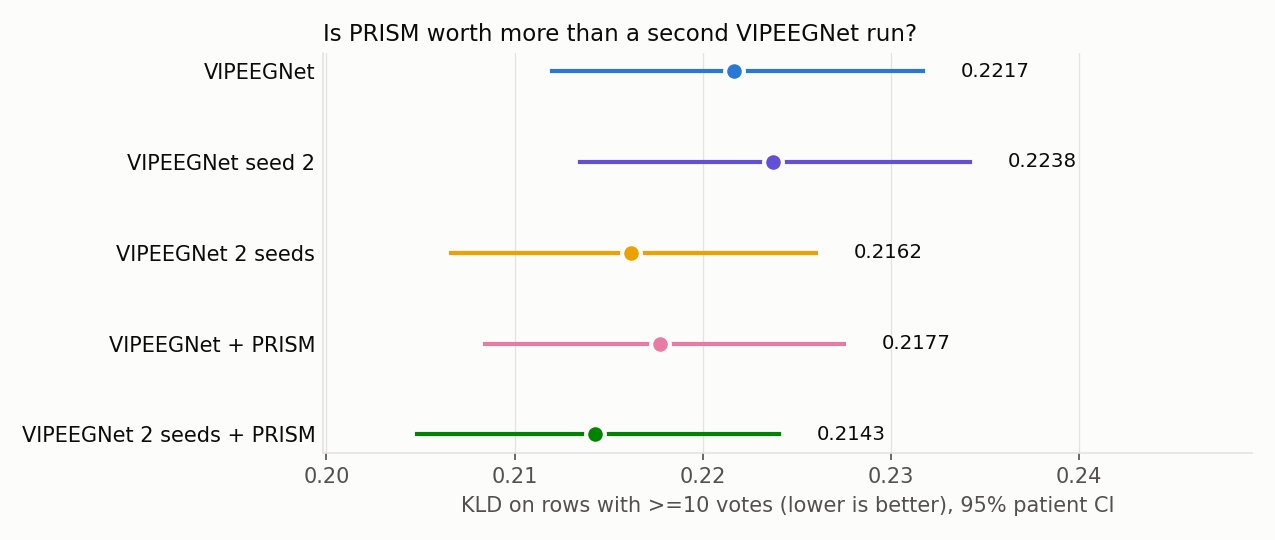

In [10]:
SG = None
if not os.path.isdir(f'{P}/results/{SEED2_TAG}'):
    print(f'{SEED2_TAG} not archived yet - section G skipped. Run it again after the second seed finishes.')
else:
    yg, mg, pg, fg = align([MODELS[0], [SEED2_TAG, 'VIPEEGNet seed 2'], MODELS[2], MODELS[3]], 'hq')
    assert np.allclose(yg, yt), 'row order differs'
    fv = fg[REF]; W = np.round(np.arange(0, 1.001, 0.05), 2)
    pg['VIPEEGNet 2 seeds'] = norm((pg[REF] + pg['VIPEEGNet seed 2']) / 2)
    b2 = np.zeros_like(yg)
    for k in np.unique(fv):
        tr, te = fv != k, fv == k
        w = W[np.argmin([kld(yg[tr], geo(pg['VIPEEGNet 2 seeds'][tr], pg['PRISM'][tr], w)).mean() for w in W])]
        b2[te] = geo(pg['VIPEEGNet 2 seeds'][te], pg['PRISM'][te], w)
    pg['VIPEEGNet 2 seeds + PRISM'] = b2
    order = [REF, 'VIPEEGNet seed 2', 'VIPEEGNet 2 seeds', BLEND, 'VIPEEGNet 2 seeds + PRISM']
    Kg = {n: kld(yg, pg[n]) for n in order}
    bsI = rng.integers(0, NP, (N_BOOT, NP)); c = np.bincount(inv)
    def pboot(x): s = np.bincount(inv, x); return s[bsI].sum(1) / c[bsI].sum(1)
    rows = []
    for n in order:
        b = pboot(Kg[n]); rows.append({'model': n, 'KLD': Kg[n].mean(), 'CI low': np.percentile(b, 2.5), 'CI high': np.percentile(b, 97.5),
                                       'accuracy %': (pg[n].argmax(1) == Y).mean() * 100})
    SG = pd.DataFrame(rows).set_index('model')
    tests = [('VIPEEGNet seed 2', REF, 'seed-to-seed noise'), ('VIPEEGNet 2 seeds', REF, 'gain from a second VIPEEGNet'),
             (BLEND, REF, 'gain from adding PRISM'), (BLEND, 'VIPEEGNet 2 seeds', 'KEY: PRISM vs a second VIPEEGNet'),
             ('VIPEEGNet 2 seeds + PRISM', 'VIPEEGNet 2 seeds', 'PRISM on top of two seeds')]
    trow = []
    for a, b, what in tests:
        d = pboot(Kg[a] - Kg[b]); trow.append({'test': what, 'comparison': f'{a} - {b}', 'KLD difference': (Kg[a] - Kg[b]).mean(),
                                               'CI low': np.percentile(d, 2.5), 'CI high': np.percentile(d, 97.5),
                                               'p': float(2 * norm_dist.sf(abs((Kg[a] - Kg[b]).mean()) / max(d.std(ddof=1), 1e-12)))})
    SGt = pd.DataFrame(trow).set_index('test')
    SG.to_csv(f'{OUTD}/g_seed_control.csv'); SGt.to_csv(f'{OUTD}/g_seed_control_tests.csv')
    REPORT += ['## G. Seed control', mdt(SG), mdt(SGt)]
    display(SG.round(4)); display(SGt.round(4))
    fig, ax = plt.subplots(figsize=(8.5, 3.6)); yy = np.arange(len(order))[::-1]
    for y_, n in zip(yy, order):
        r = SG.loc[n]; ax.plot([r['CI low'], r['CI high']], [y_, y_], color=COL[n], lw=2)
        ax.plot(r.KLD, y_, 'o', ms=9, color=COL[n], mec=SURF, mew=2)
        ax.text(r['CI high'] + 0.002, y_, f'{r.KLD:.4f}', va='center', color=INK, fontsize=9.5)
    ax.set_yticks(yy, order); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
    ax.set_xlim(SG['CI low'].min() - 0.005, SG['CI high'].max() + 0.015)
    ax.set_xlabel('KLD on rows with >=10 votes (lower is better), 95% patient CI')
    ax.set_title('Is PRISM worth more than a second VIPEEGNet run?', loc='left', fontsize=11, color=INK)
    fig.tight_layout(); save(fig, 'fig_g_seed_control.png')

## H. Three-seed control
Same question with three models on each side: **two VIPEEGNet seeds + PRISM** vs **three VIPEEGNet seeds** (equal-weight
average). If PRISM brings something a VIPEEGNet re-run cannot, the first should win. Also: the spread of three single
seeds, and three seeds + PRISM. PRISM's weight is chosen on the other four folds, as everywhere else.

PRISM weight per fold: on top of 2 seeds [0.15, 0.15, 0.15, 0.15, 0.15] | on top of 3 seeds [0.15, 0.15, 0.1, 0.15, 0.15]
single seeds: mean 0.2231, SD 0.0013, range 0.0022


,models in it,KLD,CI low,CI high,accuracy %
model,,,,,
VIPEEGNet,1,0.2217,0.2121,0.2308,77.2441
VIPEEGNet seed 2,1,0.2238,0.2136,0.2336,77.4646
VIPEEGNet seed 3,1,0.2239,0.2141,0.2337,77.6378
VIPEEGNet 2 seeds,2,0.2162,0.2070,0.2252,77.7008
VIPEEGNet 3 seeds,3,0.2145,0.2054,0.2237,78.0000
VIPEEGNet 2 seeds + PRISM,3,0.2143,0.2048,0.2232,77.5748
VIPEEGNet 3 seeds + PRISM,4,0.2131,0.2038,0.2223,77.9528


,comparison,KLD difference,CI low,CI high,p
test,,,,,
gain from a third VIPEEGNet,VIPEEGNet 3 seeds - VIPEEGNet 2 seeds,-0.0017,-0.0026,-0.0007,0.0005
gain from PRISM as the third model,VIPEEGNet 2 seeds + PRISM - VIPEEGNet 2 seeds,-0.0020,-0.0031,-0.0009,0.0005
KEY: PRISM vs a third VIPEEGNet (3 models each),VIPEEGNet 2 seeds + PRISM - VIPEEGNet 3 seeds,-0.0003,-0.0017,0.0011,0.7188
PRISM on top of three seeds,VIPEEGNet 3 seeds + PRISM - VIPEEGNet 3 seeds,-0.0014,-0.0025,-0.0004,0.0065


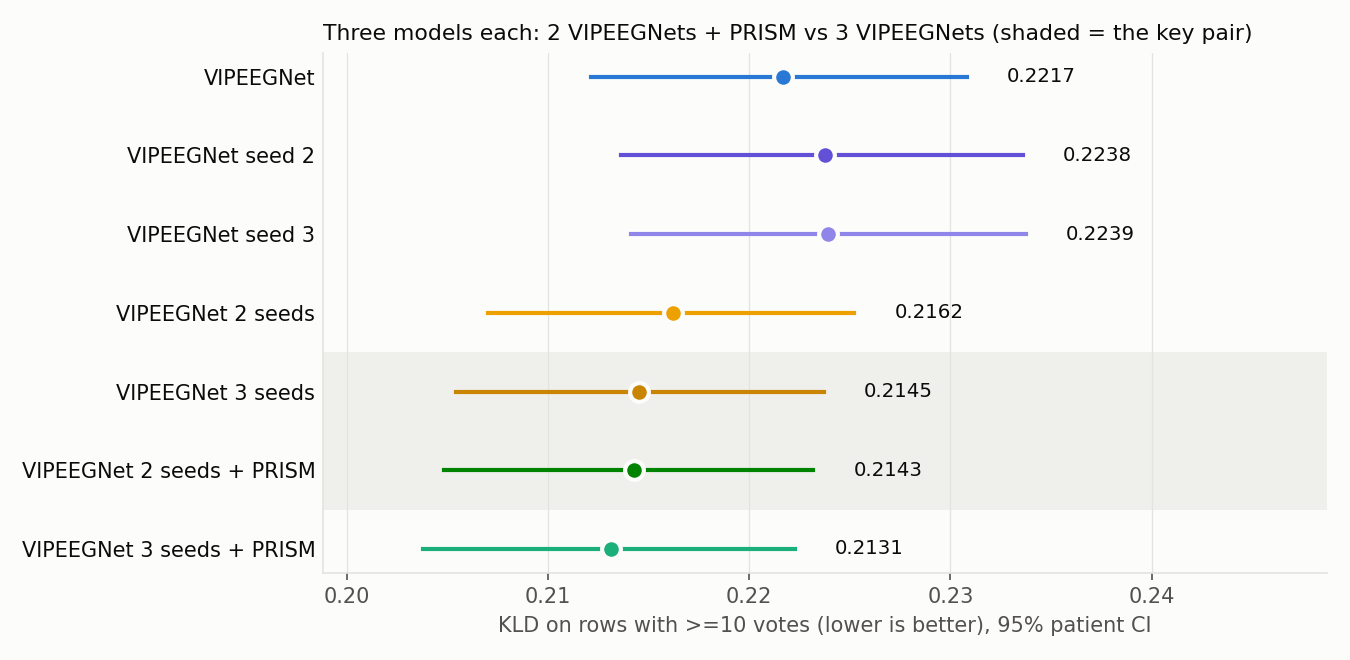

In [11]:
SH = None
if not (os.path.isdir(f'{P}/results/{SEED2_TAG}') and os.path.isdir(f'{P}/results/{SEED3_TAG}')):
    print(f'{SEED3_TAG} (or {SEED2_TAG}) not archived yet - section H skipped.')
else:
    S1, S2, S3 = REF, 'VIPEEGNet seed 2', 'VIPEEGNet seed 3'
    yh, mh, ph, fh = align([MODELS[0], [SEED2_TAG, S2], [SEED3_TAG, S3], MODELS[2]], 'hq')
    assert np.allclose(yh, yt), 'row order differs'
    fv = fh[REF]; W = np.round(np.arange(0, 1.001, 0.05), 2)
    def lofo_geo(a, b):
        out = np.zeros_like(yh); ws = []
        for k in np.unique(fv):
            tr, te = fv != k, fv == k
            w = W[np.argmin([kld(yh[tr], geo(a[tr], b[tr], w)).mean() for w in W])]; out[te] = geo(a[te], b[te], w); ws.append(float(w))
        return out, ws
    ph['VIPEEGNet 2 seeds'] = norm((ph[S1] + ph[S2]) / 2)
    ph['VIPEEGNet 3 seeds'] = norm((ph[S1] + ph[S2] + ph[S3]) / 3)
    ph['VIPEEGNet 2 seeds + PRISM'], w2 = lofo_geo(ph['VIPEEGNet 2 seeds'], ph['PRISM'])
    ph['VIPEEGNet 3 seeds + PRISM'], w3 = lofo_geo(ph['VIPEEGNet 3 seeds'], ph['PRISM'])
    print('PRISM weight per fold: on top of 2 seeds', w2, '| on top of 3 seeds', w3)
    order = [S1, S2, S3, 'VIPEEGNet 2 seeds', 'VIPEEGNet 3 seeds', 'VIPEEGNet 2 seeds + PRISM', 'VIPEEGNet 3 seeds + PRISM']
    Kh = {n: kld(yh, ph[n]) for n in order}
    bsI = rng.integers(0, NP, (N_BOOT, NP)); c = np.bincount(inv)
    def pboot(x): s = np.bincount(inv, x); return s[bsI].sum(1) / c[bsI].sum(1)
    rows = []
    for n in order:
        b = pboot(Kh[n]); rows.append({'model': n, 'models in it': 1 if n in (S1, S2, S3) else int(n[10]) + ('PRISM' in n),
                                       'KLD': Kh[n].mean(), 'CI low': np.percentile(b, 2.5), 'CI high': np.percentile(b, 97.5),
                                       'accuracy %': (ph[n].argmax(1) == Y).mean() * 100})
    SH = pd.DataFrame(rows).set_index('model')
    singles = SH.loc[[S1, S2, S3], 'KLD']
    print(f'single seeds: mean {singles.mean():.4f}, SD {singles.std():.4f}, range {singles.max() - singles.min():.4f}')
    tests = [('VIPEEGNet 3 seeds', 'VIPEEGNet 2 seeds', 'gain from a third VIPEEGNet'),
             ('VIPEEGNet 2 seeds + PRISM', 'VIPEEGNet 2 seeds', 'gain from PRISM as the third model'),
             ('VIPEEGNet 2 seeds + PRISM', 'VIPEEGNet 3 seeds', 'KEY: PRISM vs a third VIPEEGNet (3 models each)'),
             ('VIPEEGNet 3 seeds + PRISM', 'VIPEEGNet 3 seeds', 'PRISM on top of three seeds')]
    trow = []
    for a, b, what in tests:
        d = pboot(Kh[a] - Kh[b]); diff = (Kh[a] - Kh[b]).mean()
        trow.append({'test': what, 'comparison': f'{a} - {b}', 'KLD difference': diff, 'CI low': np.percentile(d, 2.5),
                     'CI high': np.percentile(d, 97.5), 'p': float(2 * norm_dist.sf(abs(diff) / max(d.std(ddof=1), 1e-12)))})
    SHt = pd.DataFrame(trow).set_index('test')
    SH.to_csv(f'{OUTD}/h_three_seed_control.csv'); SHt.to_csv(f'{OUTD}/h_three_seed_tests.csv')
    REPORT += ['## H. Three-seed control', f'Single seeds: mean {singles.mean():.4f}, SD {singles.std():.4f}. PRISM weights: 2 seeds {w2}, 3 seeds {w3}',
               mdt(SH), mdt(SHt)]
    display(SH.round(4)); display(SHt.round(4))
    HC = {S1: COL[REF], S2: COL['VIPEEGNet seed 2'], S3: '#9085e9', 'VIPEEGNet 2 seeds': COL['VIPEEGNet 2 seeds'],
          'VIPEEGNet 3 seeds': '#c98500', 'VIPEEGNet 2 seeds + PRISM': COL['VIPEEGNet 2 seeds + PRISM'], 'VIPEEGNet 3 seeds + PRISM': '#1baf7a'}
    fig, ax = plt.subplots(figsize=(9, 4.4)); yy = np.arange(len(order))[::-1]
    for y_, n in zip(yy, order):
        r = SH.loc[n]; ax.plot([r['CI low'], r['CI high']], [y_, y_], color=HC[n], lw=2)
        ax.plot(r.KLD, y_, 'o', ms=9, color=HC[n], mec=SURF, mew=2)
        ax.text(r['CI high'] + 0.002, y_, f'{r.KLD:.4f}', va='center', color=INK, fontsize=9.5)
    ax.axhspan(0.5, 2.5, color=GRID, alpha=0.5, lw=0)
    ax.set_yticks(yy, order); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
    ax.set_xlim(SH['CI low'].min() - 0.005, SH['CI high'].max() + 0.015)
    ax.set_xlabel('KLD on rows with >=10 votes (lower is better), 95% patient CI')
    ax.set_title('Three models each: 2 VIPEEGNets + PRISM vs 3 VIPEEGNets (shaded = the key pair)', loc='left', fontsize=10.5, color=INK)
    fig.tight_layout(); save(fig, 'fig_h_three_seed_control.png')

In [12]:
open(f'{OUTD}/report.md', 'w').write('\n\n'.join(REPORT + ['\n'.join(f'![{f}]({f})' for f in sorted(x for x in os.listdir(OUTD) if x.endswith('.png')))]))
print('saved to', OUTD); print(sorted(os.listdir(OUTD)))

saved to /home/nfs/jhb-dehzangi/ws04/gs1147/hms/results/comparisons/extended_eval
['a_statistics.csv', 'b_low_vote_differences.csv', 'b_low_vote_rows.csv', 'c_decision_curves.csv', 'd_error_plausibility.csv', 'e_calibration_fix.csv', 'f_signal_quality_per_row.csv', 'f_signal_quality_subgroups.csv', 'fig_c_decision_curves.png', 'fig_d_error_plausibility.png', 'fig_f_signal_quality.png', 'fig_g_seed_control.png', 'fig_h_three_seed_control.png', 'g_seed_control.csv', 'g_seed_control_tests.csv', 'h_three_seed_control.csv', 'h_three_seed_tests.csv', 'report.md']
